In [2]:
import os
from pathlib import Path

import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

load_dotenv(Path.cwd().parent / ".env")

db_url = URL.create(
    drivername="postgresql+psycopg",
    username=os.getenv("POSTGRES_USER"),
    password=os.getenv("POSTGRES_PASSWORD"),
    host="127.0.0.1",
    port=5433,
    database=os.getenv("POSTGRES_DB"),
)

engine = create_engine(db_url)

with engine.connect() as conn:
    result = conn.execute(text("SELECT current_database(), current_user"))
    print(result.fetchone())

('northstar_retail', 'northstar')


In [119]:
df_orders = pd.read_sql("SELECT * FROM orders", engine)
df_items = pd.read_sql("SELECT * FROM order_items", engine)
df_products = pd.read_sql("SELECT * FROM products", engine)
df_categories = pd.read_sql("SELECT * FROM categories", engine)

In [33]:
df_orders.dtypes, '-------', df_items.dtypes, '-------', df_products.dtypes

(order_id                         int64
 customer_id                      int64
 order_ts           datetime64[us, UTC]
 order_status                       str
 subtotal                       float64
 discount_amount                float64
 tax_amount                     float64
 shipping_fee                   float64
 total_amount                   float64
 dtype: object,
 '-------',
 order_item_id        int64
 order_id             int64
 product_id           int64
 quantity             int64
 unit_price         float64
 unit_cost          float64
 line_subtotal      float64
 discount_amount    float64
 discount_code          str
 dtype: object,
 '-------',
 product_id        int64
 category_id       int64
 sku                 str
 product_name        str
 list_price      float64
 unit_cost       float64
 is_active          bool
 dtype: object)

In [34]:
df_orders.shape, '-------', df_items.shape, '-------', df_products.shape

((25000, 9), '-------', (65854, 9), '-------', (300, 7))

In [47]:
df_orders.isna().sum(), '-------', df_items.isna().sum(), '-------', df_products.isna().sum()

(order_id           0
 customer_id        0
 order_ts           0
 order_status       0
 subtotal           0
 discount_amount    0
 tax_amount         0
 shipping_fee       0
 total_amount       0
 dtype: int64,
 '-------',
 order_item_id          0
 order_id               0
 product_id             0
 quantity               0
 unit_price             0
 unit_cost              0
 line_subtotal          0
 discount_amount        0
 discount_code      43646
 dtype: int64,
 '-------',
 product_id      0
 category_id     0
 sku             0
 product_name    0
 list_price      0
 unit_cost       0
 is_active       0
 dtype: int64)

In [36]:
df_orders.notna().shape, '-------', df_items.notna().shape, '-------', df_products.notna().shape

((25000, 9), '-------', (65854, 9), '-------', (300, 7))

In [37]:
df_orders.duplicated().sum(), df_items.duplicated().sum(), df_products.duplicated().sum()

(np.int64(0), np.int64(0), np.int64(0))

In [39]:
df_orders.head(5), '-------', df_items.head(5), '-------', df_products.head(5)

(   order_id  customer_id                  order_ts order_status  subtotal  \
 0         1         2499 2024-05-19 14:54:33+00:00      shipped    130.33   
 1         2          592 2025-07-12 23:01:45+00:00         paid     39.52   
 2         3         2516 2024-11-08 04:17:56+00:00         paid    378.80   
 3         4         3141 2024-12-24 12:51:44+00:00    delivered    300.24   
 4         5         3927 2024-06-24 11:46:54+00:00      shipped    221.02   
 
    discount_amount  tax_amount  shipping_fee  total_amount  
 0             0.00       10.43          0.00        140.76  
 1             0.00        3.16          6.95         49.63  
 2            24.83       28.32          0.00        382.29  
 3             5.37       23.59          0.00        318.46  
 4             6.58       17.16          0.00        231.60  ,
 '-------',
    order_item_id  order_id  product_id  quantity  unit_price  unit_cost  \
 0              1         1          74         2       37.49      25

In [40]:
df_orders.tail(5), '-------', df_items.tail(5), '-------', df_products.tail(5)

(       order_id  customer_id                  order_ts order_status  subtotal  \
 24995     24996         1766 2025-05-09 19:31:19+00:00    delivered    100.06   
 24996     24997         2436 2024-10-06 10:28:18+00:00    delivered    273.85   
 24997     24998         4000 2025-04-27 11:24:47+00:00         paid    146.13   
 24998     24999         2712 2024-10-06 03:46:04+00:00    cancelled    109.03   
 24999     25000         4878 2024-03-16 22:25:36+00:00    delivered     78.79   
 
        discount_amount  tax_amount  shipping_fee  total_amount  
 24995             4.05        7.68          0.00        103.69  
 24996            31.32       19.40          0.00        261.93  
 24997             4.18       11.36          0.00        153.31  
 24998             2.82        8.50          0.00        114.71  
 24999             4.06        5.98          6.95         87.66  ,
 '-------',
        order_item_id  order_id  product_id  quantity  unit_price  unit_cost  \
 65849          6

In [43]:
df_orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype              
---  ------           --------------  -----              
 0   order_id         25000 non-null  int64              
 1   customer_id      25000 non-null  int64              
 2   order_ts         25000 non-null  datetime64[us, UTC]
 3   order_status     25000 non-null  str                
 4   subtotal         25000 non-null  float64            
 5   discount_amount  25000 non-null  float64            
 6   tax_amount       25000 non-null  float64            
 7   shipping_fee     25000 non-null  float64            
 8   total_amount     25000 non-null  float64            
dtypes: datetime64[us, UTC](1), float64(5), int64(2), str(1)
memory usage: 1.7 MB


In [44]:
df_items.info()

<class 'pandas.DataFrame'>
RangeIndex: 65854 entries, 0 to 65853
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_item_id    65854 non-null  int64  
 1   order_id         65854 non-null  int64  
 2   product_id       65854 non-null  int64  
 3   quantity         65854 non-null  int64  
 4   unit_price       65854 non-null  float64
 5   unit_cost        65854 non-null  float64
 6   line_subtotal    65854 non-null  float64
 7   discount_amount  65854 non-null  float64
 8   discount_code    22208 non-null  str    
dtypes: float64(4), int64(4), str(1)
memory usage: 4.5 MB


In [45]:
df_products.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   product_id    300 non-null    int64  
 1   category_id   300 non-null    int64  
 2   sku           300 non-null    str    
 3   product_name  300 non-null    str    
 4   list_price    300 non-null    float64
 5   unit_cost     300 non-null    float64
 6   is_active     300 non-null    bool   
dtypes: bool(1), float64(2), int64(2), str(2)
memory usage: 14.5 KB


In [ ]:
(df_items.discount_amount == 0).sum(), (df_items.discount_code.isnull()).sum()

(np.int64(43684), np.int64(43646))

In [57]:
(df_items.discount_amount != 0).sum(), (df_items.discount_code.notnull()).sum()

(np.int64(22170), np.int64(22208))

In [58]:
(df_items.discount_amount == 0).sum() + (df_items.discount_amount != 0).sum()

np.int64(65854)

In [59]:
(df_items.discount_code.isnull()).sum() + (df_items.discount_code.notnull()).sum()

np.int64(65854)

In [73]:
mask = (
    (df_items.discount_amount > 0) &
    (df_items.discount_code.isnull())
)

mask.sum()

np.int64(0)

In [74]:
mask = (
    (df_items.discount_amount == 0) &
    (df_items.discount_code.notnull())
)

mask.sum()

np.int64(38)

In [75]:
suspicious_items = df_items.loc[
    (df_items["discount_amount"] == 0)
    & (df_items["discount_code"].notna())
]

suspicious_items.head()

,order_item_id,order_id,product_id,quantity,unit_price,unit_cost,line_subtotal,discount_amount,discount_code
1823,1824,701,144,1,13.59,9.59,13.59,0.0,MYSTERY_DEAL
4875,4876,1856,236,1,52.55,37.18,52.55,0.0,MYSTERY_DEAL
6389,6390,2412,129,2,34.41,24.78,68.82,0.0,MYSTERY_DEAL
6831,6832,2580,29,1,32.03,18.11,32.03,0.0,MYSTERY_DEAL
6865,6866,2594,1,1,52.44,38.02,52.44,0.0,MYSTERY_DEAL


In [120]:
orders = df_orders.rename(
    columns={"discount_amount": "order_discount"}
)

items = df_items.rename(
    columns={
        "discount_amount": "item_discount",
        "unit_cost": "item_unit_cost"
    }
)

products = df_products.rename(
    columns={"unit_cost": "catalog_unit_cost"}
)

df_sales = (
    orders
    .merge(
        items,
        on="order_id",
        how="inner",
        validate="one_to_many"
    )
    .merge(
        products,
        on="product_id",
        how="inner",
        validate="many_to_one"
    )
    .merge(
        df_categories,
        on="category_id",
        how="inner",
        validate="many_to_one"
    )
)


In [121]:
df_sales.head(5)

,order_id,customer_id,order_ts,order_status,subtotal,order_discount,tax_amount,shipping_fee,total_amount,order_item_id,...,item_discount,discount_code,category_id,sku,product_name,list_price,catalog_unit_cost,is_active,category_name,description
0,1,2499,2024-05-19 14:54:33+00:00,shipped,130.33,0.00,10.43,0.00,140.76,1,...,0.00,NaN,4,NS-04-0074,Summit Backpack 074,38.42,27.48,True,Beauty,Northstar beauty assortment
1,1,2499,2024-05-19 14:54:33+00:00,shipped,130.33,0.00,10.43,0.00,140.76,2,...,0.00,NaN,4,NS-04-0044,Summit Backpack 044,37.24,25.78,True,Beauty,Northstar beauty assortment
2,1,2499,2024-05-19 14:54:33+00:00,shipped,130.33,0.00,10.43,0.00,140.76,3,...,0.00,NaN,7,NS-07-0117,Heritage Bottle 117,19.08,14.01,False,Toys,Northstar toys assortment
3,2,592,2025-07-12 23:01:45+00:00,paid,39.52,0.00,3.16,6.95,49.63,4,...,0.00,NaN,7,NS-07-0177,Heritage Bottle 177,40.02,30.43,True,Toys,Northstar toys assortment
4,3,2516,2024-11-08 04:17:56+00:00,paid,378.80,24.83,28.32,0.00,382.29,5,...,22.94,CLEARANCE,7,NS-07-0097,Heritage Bottle 097,77.47,57.65,True,Toys,Northstar toys assortment


In [122]:
df_sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 65854 entries, 0 to 65853
Data columns (total 25 columns):
 #   Column             Non-Null Count  Dtype              
---  ------             --------------  -----              
 0   order_id           65854 non-null  int64              
 1   customer_id        65854 non-null  int64              
 2   order_ts           65854 non-null  datetime64[us, UTC]
 3   order_status       65854 non-null  str                
 4   subtotal           65854 non-null  float64            
 5   order_discount     65854 non-null  float64            
 6   tax_amount         65854 non-null  float64            
 7   shipping_fee       65854 non-null  float64            
 8   total_amount       65854 non-null  float64            
 9   order_item_id      65854 non-null  int64              
 10  product_id         65854 non-null  int64              
 11  quantity           65854 non-null  int64              
 12  unit_price         65854 non-null  float64            
 1

In [123]:
df_sales.isnull().sum()

order_id                 0
customer_id              0
order_ts                 0
order_status             0
subtotal                 0
order_discount           0
tax_amount               0
shipping_fee             0
total_amount             0
order_item_id            0
product_id               0
quantity                 0
unit_price               0
item_unit_cost           0
line_subtotal            0
item_discount            0
discount_code        43646
category_id              0
sku                      0
product_name             0
list_price               0
catalog_unit_cost        0
is_active                0
category_name            0
description              0
dtype: int64

In [124]:
df_sales["net_line_value"] = df_sales.line_subtotal - df_sales.item_discount
df_sales["line_cogs"] = df_sales.item_unit_cost * df_sales.quantity
df_sales["line_gross_profit"] = df_sales.net_line_value - df_sales.line_cogs
df_sales["profit_margin_pct"] = df_sales["line_gross_profit"] / df_sales["net_line_value"] * 100

In [125]:
df_sales.head()

,order_id,customer_id,order_ts,order_status,subtotal,order_discount,tax_amount,shipping_fee,total_amount,order_item_id,...,product_name,list_price,catalog_unit_cost,is_active,category_name,description,net_line_value,line_cogs,line_gross_profit,profit_margin_pct
0,1,2499,2024-05-19 14:54:33+00:00,shipped,130.33,0.00,10.43,0.00,140.76,1,...,Summit Backpack 074,38.42,27.48,True,Beauty,Northstar beauty assortment,74.98,50.52,24.46,32.622033
1,1,2499,2024-05-19 14:54:33+00:00,shipped,130.33,0.00,10.43,0.00,140.76,2,...,Summit Backpack 044,37.24,25.78,True,Beauty,Northstar beauty assortment,36.57,23.84,12.73,34.809954
2,1,2499,2024-05-19 14:54:33+00:00,shipped,130.33,0.00,10.43,0.00,140.76,3,...,Heritage Bottle 117,19.08,14.01,False,Toys,Northstar toys assortment,18.78,12.97,5.81,30.937167
3,2,592,2025-07-12 23:01:45+00:00,paid,39.52,0.00,3.16,6.95,49.63,4,...,Heritage Bottle 177,40.02,30.43,True,Toys,Northstar toys assortment,39.52,30.34,9.18,23.228745
4,3,2516,2024-11-08 04:17:56+00:00,paid,378.80,24.83,28.32,0.00,382.29,5,...,Heritage Bottle 097,77.47,57.65,True,Toys,Northstar toys assortment,206.44,158.55,47.89,23.198024


In [129]:
df_category = (
    df_sales
    .groupby("category_name")
    .agg(
        net_sales = ("net_line_value", "sum"),
        cogs = ("line_cogs", "sum"),
        gross_profit = ("line_gross_profit", "sum")
    )
    .reset_index()
)

df_category

,category_name,net_sales,cogs,gross_profit
0,Apparel,272320.18,187579.76,84740.42
1,Beauty,310166.07,212079.62,98086.45
2,Books,294080.86,203033.22,91047.64
3,Electronics,297886.49,203392.06,94494.43
4,Grocery,347832.25,238005.51,109826.74
5,Home & Kitchen,343259.82,232484.59,110775.23
6,Office,301974.37,203693.65,98280.72
7,Pet Supplies,317821.05,219516.29,98304.76
8,Sports & Outdoors,298715.30,207749.82,90965.48
9,Toys,304718.55,213944.21,90774.34


In [130]:
import numpy as np

df_category["profit_margin_pct"] = np.where(
    df_category["net_sales"] != 0,
    df_category["gross_profit"] / df_category["net_sales"] * 100,
    np.nan
)

df_category["profit_margin_pct"] = (
    df_category["profit_margin_pct"].round(2)
)

In [131]:
print(df_sales["net_line_value"].sum())
print(df_category["net_sales"].sum())

3088774.94
3088774.9399999995


In [153]:
df_category=df_category.sort_values("gross_profit", ascending=False).reset_index(drop=True)

In [154]:
df_category

,category_name,net_sales,cogs,gross_profit,profit_margin_pct
0,Home & Kitchen,343259.82,232484.59,110775.23,32.27
1,Grocery,347832.25,238005.51,109826.74,31.57
2,Pet Supplies,317821.05,219516.29,98304.76,30.93
3,Office,301974.37,203693.65,98280.72,32.55
4,Beauty,310166.07,212079.62,98086.45,31.62
5,Electronics,297886.49,203392.06,94494.43,31.72
6,Books,294080.86,203033.22,91047.64,30.96
7,Sports & Outdoors,298715.30,207749.82,90965.48,30.45
8,Toys,304718.55,213944.21,90774.34,29.79
9,Apparel,272320.18,187579.76,84740.42,31.12


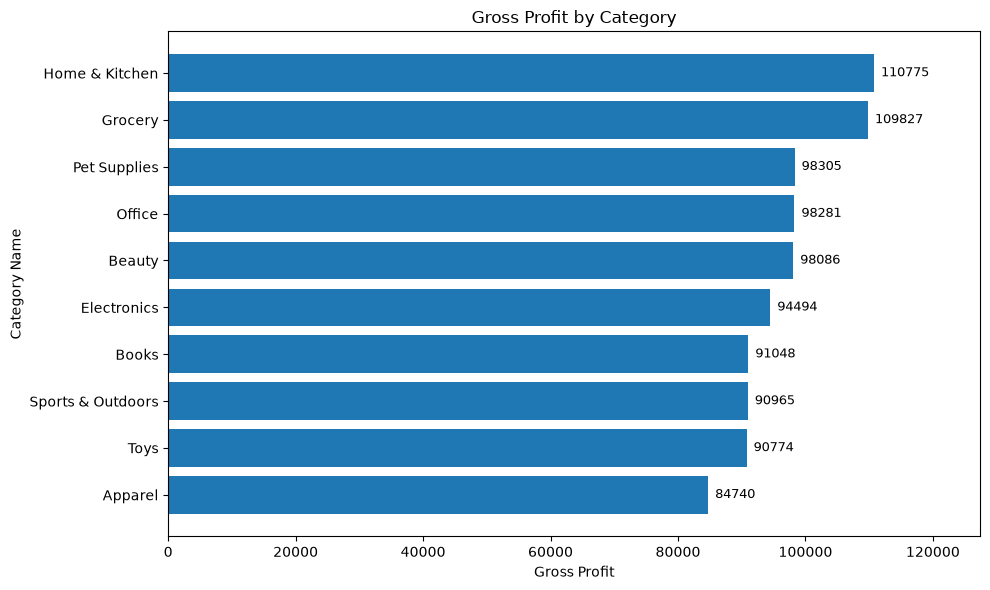

In [276]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

ax.set_xlabel("Gross Profit")
ax.set_ylabel("Category Name")
ax.set_title("Gross Profit by Category")

ax.invert_yaxis()

bars = ax.barh(
    df_category["category_name"],
    df_category["gross_profit"]
)
ax.bar_label(
    bars,
    fmt="%.0f",
    padding=5,
    fontsize=9
)
ax.set_xlim(0, df_category["gross_profit"].max() * 1.15)

plt.tight_layout()
plt.show()

In [162]:
df_sales["month"] = (
    df_sales["order_ts"]
    .dt.tz_convert("UTC")
    .dt.tz_localize(None)
    .dt.to_period("M")
)

In [163]:
df_sales.head()

,order_id,customer_id,order_ts,order_status,subtotal,order_discount,tax_amount,shipping_fee,total_amount,order_item_id,...,list_price,catalog_unit_cost,is_active,category_name,description,net_line_value,line_cogs,line_gross_profit,profit_margin_pct,month
0,1,2499,2024-05-19 14:54:33+00:00,shipped,130.33,0.00,10.43,0.00,140.76,1,...,38.42,27.48,True,Beauty,Northstar beauty assortment,74.98,50.52,24.46,32.622033,2024-05
1,1,2499,2024-05-19 14:54:33+00:00,shipped,130.33,0.00,10.43,0.00,140.76,2,...,37.24,25.78,True,Beauty,Northstar beauty assortment,36.57,23.84,12.73,34.809954,2024-05
2,1,2499,2024-05-19 14:54:33+00:00,shipped,130.33,0.00,10.43,0.00,140.76,3,...,19.08,14.01,False,Toys,Northstar toys assortment,18.78,12.97,5.81,30.937167,2024-05
3,2,592,2025-07-12 23:01:45+00:00,paid,39.52,0.00,3.16,6.95,49.63,4,...,40.02,30.43,True,Toys,Northstar toys assortment,39.52,30.34,9.18,23.228745,2025-07
4,3,2516,2024-11-08 04:17:56+00:00,paid,378.80,24.83,28.32,0.00,382.29,5,...,77.47,57.65,True,Toys,Northstar toys assortment,206.44,158.55,47.89,23.198024,2024-11


In [193]:
df_month_margin = (
    df_sales.groupby("month")
    .agg(
        net_sales = ("net_line_value", "sum"),
        gross_profit = ("line_gross_profit", "sum"),
        cogs = ("line_cogs", "sum")
    ).reset_index()
)

In [194]:
df_month_margin["gross_margin_pct"] = np.where(
    df_month_margin["net_sales"] != 0,
    df_month_margin["gross_profit"] / df_month_margin["net_sales"] * 100,
    np.nan
)

In [195]:
df_month_margin.gross_margin_pct = (df_month_margin.gross_margin_pct.round(2))

In [196]:
df_month_margin

,month,net_sales,gross_profit,cogs,gross_margin_pct
0,2024-01,100851.38,33805.35,67046.03,33.52
1,2024-02,89129.31,29508.74,59620.57,33.11
2,2024-03,100372.32,33347.58,67024.74,33.22
3,2024-04,102394.98,34230.95,68164.03,33.43
4,2024-05,116173.47,38486.01,77687.46,33.13
5,2024-06,108777.82,36320.51,72457.31,33.39
6,2024-07,123975.94,41179.74,82796.20,33.22
7,2024-08,121793.29,40707.65,81085.64,33.42
8,2024-09,123074.18,41501.35,81572.83,33.72
9,2024-10,135444.05,45204.09,90239.96,33.37


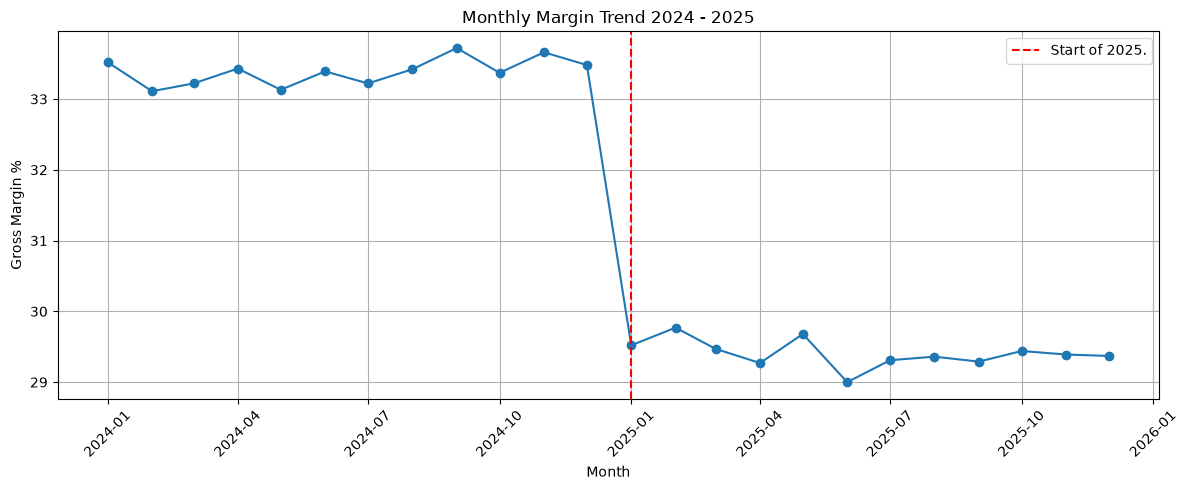

In [200]:
fig2, ax2 = plt.subplots(figsize=(12, 5))
x = df_month_margin["month"].dt.to_timestamp()
y = df_month_margin["gross_margin_pct"]
ax2.plot(x, y, marker='o')
ax2.set_xlabel("Month")
ax2.set_ylabel("Gross Margin %")
ax2.set_title("Monthly Margin Trend 2024 - 2025")
ax2.grid(True)

ax2.axvline(x=pd.Timestamp("2025-01-01"), color='red', linestyle='--', label='Start of 2025.')
ax2.legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [208]:
df_sales["year"] = (
    df_sales["order_ts"]
    .dt.tz_convert("UTC")
    .dt.tz_localize(None)
    .dt.year
)

df_sales.columns

Index(['order_id', 'customer_id', 'order_ts', 'order_status', 'subtotal',
       'order_discount', 'tax_amount', 'shipping_fee', 'total_amount',
       'order_item_id', 'product_id', 'quantity', 'unit_price',
       'item_unit_cost', 'line_subtotal', 'item_discount', 'discount_code',
       'category_id', 'sku', 'product_name', 'list_price', 'catalog_unit_cost',
       'is_active', 'category_name', 'description', 'net_line_value',
       'line_cogs', 'line_gross_profit', 'profit_margin_pct', 'month', 'year'],
      dtype='str')

In [228]:
df_yearly = df_sales.groupby("year").agg(
    quantity=("quantity", "sum"),
    line_subtotal=("line_subtotal", "sum"),
    item_discount=("item_discount", "sum"),
    line_cogs=("line_cogs", "sum"),
    line_gross_profit=("line_gross_profit", "sum")
)

df_yearly["avg_unit_price"] = (df_yearly["line_subtotal"] - df_yearly["item_discount"]) / df_yearly["quantity"]
df_yearly["avg_unit_cost"] = df_yearly["line_cogs"] / df_yearly["quantity"]
df_yearly["avg_unit_gross_profit"] = df_yearly["line_gross_profit"] / df_yearly["quantity"]
df_yearly["avg_unit_discount"] = df_yearly["item_discount"] / df_yearly["quantity"]
df_yearly["avg_discount_rate_pct"] = (df_yearly["item_discount"] / df_yearly["line_subtotal"] * 100).round(2)
df_yearly["gross_margin_pct"] = (df_yearly["line_gross_profit"] / (df_yearly["line_subtotal"] - df_yearly["item_discount"]) * 100).round(2)

In [229]:
df_yearly

,quantity,line_subtotal,item_discount,line_cogs,line_gross_profit,avg_unit_price,avg_unit_cost,avg_unit_gross_profit,avg_unit_discount,avg_discount_rate_pct,gross_margin_pct
year,,,,,,,,,,,
2024,38578,1536387.70,58991.62,983818.97,493577.11,38.296337,25.502073,12.794264,1.529152,3.84,33.41
2025,40696,1694765.47,83386.61,1137659.76,473719.10,39.595510,27.955076,11.640434,2.049012,4.92,29.40


In [241]:
df_category_yearly = df_sales.groupby(["year", "category_name"]).agg(
    units_sold=("quantity", "sum"),
    net_sales=("net_line_value", "sum"),
    line_cogs=("line_cogs", "sum"),
    line_gross_profit=("line_gross_profit", "sum")
)
df_category_yearly["net_asp"] = df_category_yearly["net_sales"] / df_category_yearly["units_sold"]
df_category_yearly["avg_unit_cost"] = df_category_yearly["line_cogs"] / df_category_yearly["units_sold"]
df_category_yearly["gross_margin_pct"] = (df_category_yearly["line_gross_profit"] / df_category_yearly["net_sales"].replace(0, np.nan) * 100).round(2)
df_category_yearly

units_sold  net_sales  line_cogs  line_gross_profit  \
year category_name                                                            
2024 Apparel                  3849  131047.91   87264.25           43783.66   
     Beauty                   3817  148257.46   98104.84           50152.62   
     Books                    3796  140135.59   93666.84           46468.75   
     Electronics              3988  149359.69   99056.37           50303.32   
     Grocery                  3889  163110.98  108806.26           54304.72   
     Home & Kitchen           3876  159777.05  104795.05           54982.00   
     Office                   3771  144397.75   94307.06           50090.69   
     Pet Supplies             3906  152254.55  102243.17           50011.38   
     Sports & Outdoors        3890  141286.79   94954.14           46332.65   
     Toys                     3796  147768.31  100620.99           47147.32   
2025 Apparel                  4068  141272.27  100315.51           40956.76   
     Beauty                   3964  161908.61  113974.78           47933.83   
     Books                    3978  153945.27  109366.38           44578.89   
     Electronics              3930  148526.80  104335.69           44191.11   
     Grocery                  4197  184721.27  129199.25           55522.02   
     Home & Kitchen           4281  183482.77  127689.54           55793.23   
     Office                   3998  157576.62  109386.59           48190.03   
     Pet Supplies             4107  165566.50  117273.12           48293.38   
     Sports & Outdoors        4182  157428.51  112795.68           44632.83   
     Toys                     3991  156950.24  113323.22           43627.02   

                          net_asp  avg_unit_cost  gross_margin_pct  
year category_name                                                  
2024 Apparel            34.047262      22.671928             33.41  
     Beauty             38.841357      25.702080             33.83  
     Books              36.916646      24.675142             33.16  
     Electronics        37.452279      24.838608             33.68  
     Grocery            41.941625      27.977953             33.29  
     Home & Kitchen     41.222149      27.036907             34.41  
     Office             38.291634      25.008502             34.69  
     Pet Supplies       38.979659      26.175927             32.85  
     Sports & Outdoors  36.320512      24.409805             32.79  
     Toys               38.927374      26.507110             31.91  
2025 Apparel            34.727697      24.659663             28.99  
     Beauty             40.844755      28.752467             29.61  
     Books              38.699163      27.492805             28.96  
     Electronics        37.793079      26.548522             29.75  
     Grocery            44.012692      30.783715             30.06  
     Home & Kitchen     42.859792      29.827036             30.41  
     Office             39.413862      27.360328             30.58  
     Pet Supplies       40.313246      28.554449             29.17  
     Sports & Outdoors  37.644311      26.971707             28.35  
     Toys               39.326044      28.394693             27.80

In [253]:
df_cost_comparison = df_category_yearly.reset_index().pivot(
        index="category_name",
        columns="year",
        values="avg_unit_cost"
    )

df_cost_comparison["cost_growth_pct"] = ((df_cost_comparison[2025] - df_cost_comparison[2024]) / df_cost_comparison[2024] * 100).round(2)
df_cost_comparison = df_cost_comparison.sort_values("cost_growth_pct", ascending=False)

df_cost_comparison = df_cost_comparison.rename(
    columns={
        2024: "cost_2024",
        2025: "cost_2025"
    }
)

df_cost_comparison

year,cost_2024,cost_2025,cost_growth_pct
category_name,,,
Beauty,25.702080,28.752467,11.87
Books,24.675142,27.492805,11.42
Sports & Outdoors,24.409805,26.971707,10.50
Home & Kitchen,27.036907,29.827036,10.32
Grocery,27.977953,30.783715,10.03
Office,25.008502,27.360328,9.40
Pet Supplies,26.175927,28.554449,9.09
Apparel,22.671928,24.659663,8.77
Toys,26.507110,28.394693,7.12


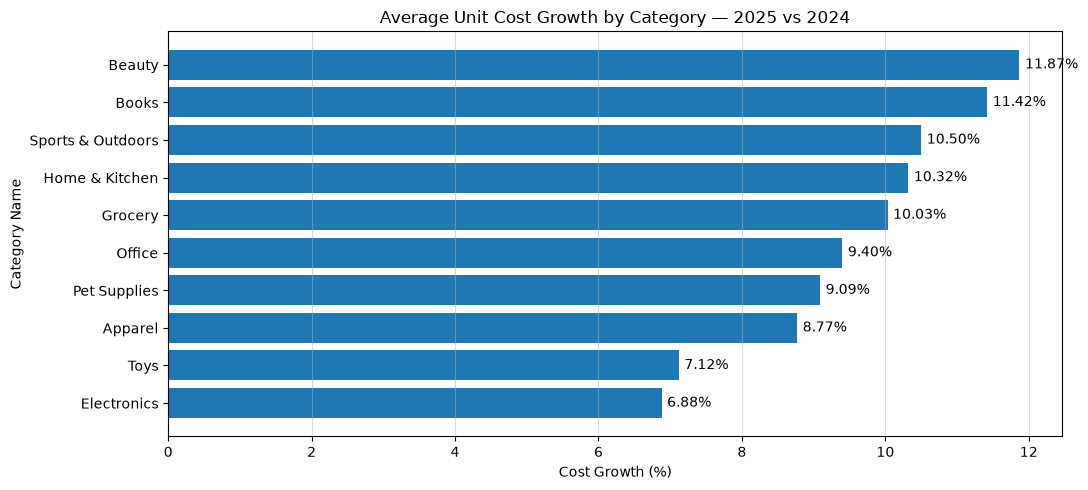

In [277]:
fig3, ax3 = plt.subplots(figsize=(11, 5))
x = df_cost_comparison.index
y = df_cost_comparison["cost_growth_pct"]
    
ax3.set_xlabel("Cost Growth (%)")
ax3.set_ylabel("Category Name")
ax3.set_title("Average Unit Cost Growth by Category — 2025 vs 2024")
ax3.grid(axis="x", alpha=0.5)
    
ax3.invert_yaxis()

bars = ax3.barh(x, y)

ax3.bar_label(
    bars,
    labels=[f"{v:.2f}%" for v in y],
    padding=4,
    fontsize=10
)

plt.tight_layout()
plt.show()
